# 18 灰色 GM 预测模型

> **模块**：灰色系统 ｜ **数据**：无（内置示例） ｜ **依赖**：numpy、pandas、matplotlib、scipy、scikit-learn 等

## 1. 问题背景

灰色预测是一种对含有不确定因素的系统进行预测的方法。灰色预测通过鉴别系统因素之间发展趋势的相异程度，即进行关联分析，并对原始数据进行生成处理来寻找系统变动的规律，生成有较强规律性的数据序列，然后建立相应的微分方程模型，从而预测事物未来发展趋势的状况。其用等时距观测到的反映预测对象特征的一系列数量值构造灰色预测模型，预测未来某一时刻的特征量，或达到某一特征量的时间。


## 2. 学习目标

- 掌握数据累加生成的原理
- 掌握灰色 GM 模型的预测


## 3. 环境与数据

- Jupyter 开发环境
- Python 3.10


## 4. 方法与实现

### 4.1 生成数

灰色系统理论把一切随机量都看作灰色数，对灰色数的处理不是找概率或求统计规律，而是利用数据处理的办法去寻找数据间的规律。

灰色系统预测的主要特点是模型使用的不是原始数据序列，而是生成的数据序列，即对原始数据作累计生成得到近似的指数规律再进行建模的方法。
这种做法的缺点是只适用于中短期的预测，**只适合指数增长的预测**。

通过对数列中的数据进行处理，产生新的数列，以此来挖掘和寻找数的规律性的方法，叫做数的生成。数的生成方式有很多种：累加生成，累减生成以及加权累加生成等等。本次实验只介绍累加生成。

#### 4.1.1 数据累加生成

**定义1**. 把数列$x^{(0)}$各时刻数据依次累加的过程叫做累加过程，累计所得的新数列，叫做累加生成数列。

设原始数列$x^{(0)} = (x^{(0)}(1),x^{(0)}(2),...,x^{(0)}(n))$，令

$$
x^{(1)}(k) = \sum^{k}_{i=1}{x^{(0)}(i)},\quad\quad k=1,2,...,n

$$
得到$x^{(1)} = (x^{(1)}(1),x^{(1)}(2),...,x^{(1)}(n))$，称$x^{(1)}$为$x^{(0)}$的一次累加生成数列。

自然有，$x^{(0)}$的$r$次累加生成数列：

$$
x^{(r)} = (x^{(r)}(1),x^{(r)}(2),...,x^{(r)}(n)); \quad x^{(r)}(k) = \sum^{k}_{i=1}{x^{(r-1)}(i)}

$$

在实际应用中，最常用的是一次累加生成。一般地，经济数列等实际问题的数据皆是非负数列，累加生成可使非负的摆动与非摆动的数列或任意无规律的数列转化为非减的数列。

<table style="width: 50%; border-collapse: collapse; margin-top: 0.5em; margin-bottom: 0.5em; font-size: 12pt; line-height: 20pt;">
<thead>
<tr>
<th style="border-bottom: 2px solid black; padding: 0.5em;">年份</th>
<th style="border-bottom: 2px solid black; padding: 0.5em;">2018</th>
<th style="border-bottom: 2px solid black; padding: 0.5em;">2019</th>
<th style="border-bottom: 2px solid black; padding: 0.5em;">2020</th>
<th style="border-bottom: 2px solid black; padding: 0.5em;">2021</th>
<th style="border-bottom: 2px solid black; padding: 0.5em;">2022</th>
<th style="border-bottom: 2px solid black; padding: 0.5em;">2023</th>
</tr>
</thead>
<tbody>
<tr>
<td style="border-top: 1px solid black; border-bottom: 1px solid black; padding: 0.5em;">销售额（亿）</td>
<td style="border-top: 1px solid black; border-bottom: 1px solid black; padding: 0.5em;">5.045</td>
<td style="border-top: 1px solid black; border-bottom: 1px solid black; padding: 0.5em;">4.536</td>
<td style="border-top: 1px solid black; border-bottom: 1px solid black; padding: 0.5em;">5.236</td>
<td style="border-top: 1px solid black; border-bottom: 1px solid black; padding: 0.5em;">9.589</td>
<td style="border-top: 1px solid black; border-bottom: 1px solid black; padding: 0.5em;">11.239</td>
<td style="border-top: 1px solid black; border-bottom: 1px solid black; padding: 0.5em;">16.762</td>
</tr>
</tbody>
</table>
表1: 某乳制品2018-2023年销售额数据


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif']=['SimHei'] 
plt.rc('axes',unicode_minus=False)
from sklearn.linear_model import LinearRegression
from scipy.optimize import curve_fit
# 用来正常显示中文标签
plt.rcParams['font.sans-serif']=['SimHei'] 
# 正常显示负号
plt.rc('axes',unicode_minus=False)
# 忽略警告提示
import warnings
warnings.filterwarnings('ignore')
t0=np.arange(1,7)
x0=np.array([5.045,4.536,5.236,9.589,11.239,16.762])

# 线性拟合
md = LinearRegression()
md.fit(t0.reshape(-1,1),x0)
print('回归参数的估计值为：\n',md.intercept_,md.coef_[0])
# 预测
x11 = md.predict(t0.reshape(-1,1))
print('预测值为：\n',x11)

# np.cumsum()计算累加和
x1=np.cumsum(x0)
# curve_fit()拟合指数曲线
def func(t,a,b,c):
    return a*np.exp(b*t)+c
# curve_fit(f, xdata, ydata, ...)
# f:拟合的函数；xdata, ydata：自变量和函数的观测值
popt, pcov=curve_fit(func, t0, x1)
# 返回值popt是拟合参数，pcov是参数的协方差矩阵
print("拟合的参数值为：", popt)
x12 = func(t0, *popt)
print("预测值分别为：",x12 )

回归参数的估计值为：
 0.4297999999999984 2.3727714285714288
预测值为：
 [ 2.80257143  5.17534286  7.54811429  9.92088571 12.29365714 14.66642857]
拟合的参数值为： [ 7.73729447  0.3363273  -5.80151578]
预测值分别为： [ 5.02912665  9.35918617 15.42039096 23.9048479  35.78136618 52.40608213]


得到原始数据线性拟合方程：$x^{(0)}(k) = 2.37k+0.42$。

累加数据指数拟合方程：$x^{(1)}(k) = 7.73e^{0.33k}-5.80$。

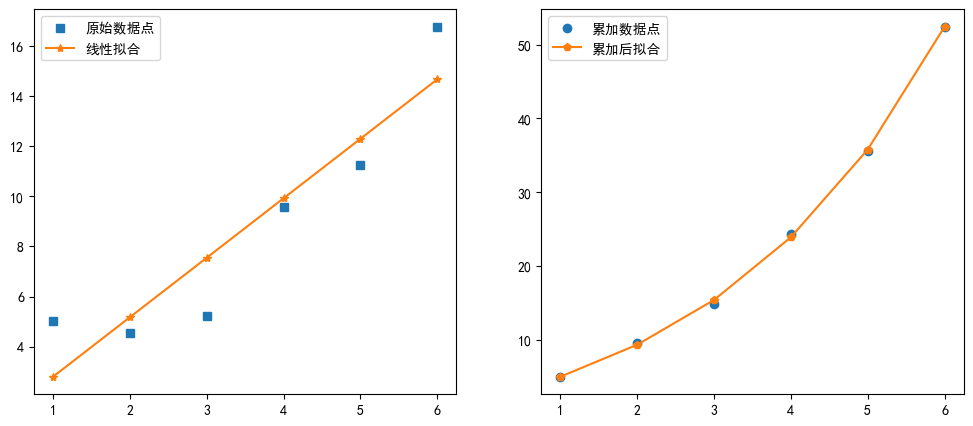

In [11]:
# 绘制图像

plt.figure(figsize = (12,5))
# 绘制一行两列两个子图
plt.subplot(121)
# 绘制原始数据点和线性拟合预测数据点
plt.plot(t0,x0,'s')
plt.plot(t0,x11,'*-')
plt.legend(('原始数据点','线性拟合'),loc='upper left')

plt.subplot(122)
# 绘制累加数据点和指数拟合预测数据点
plt.plot(t0,x1,'o')
plt.plot(t0,x12,'p-')
plt.legend(('累加数据点','累加后拟合'))
plt.show()

In [12]:
# 计算均方误差MSE
def MSE(y,y_pre):
    return (y-y_pre)**2/len(y)
# x13为累加指数拟合预测值累减还原后的值
x13 = x12.copy()
x13[1::] = np.diff(x12)
print('原数据线性拟合MSE',np.sum(MSE(x0,x11)))
print('累加数据指数拟合MSE',np.sum(MSE(x1,x12)))
print('指数预测累加数据还原后MSE',np.sum(MSE(x0,x13)))

原数据线性拟合MSE 2.7328311809523815
累加数据指数拟合MSE 0.11388066621177188
指数预测累加数据还原后MSE 0.39481970716687337


### 4.2 灰色 GM 预测模型

灰色预测是通过少量的、不完全的信息，建立数学模型做出预测的一种预测方法。该方法基于客观事物的过去和现在的发展规律，对未来的发展趋势和状况进行描述和分析，并形成科学的假设和判断。其中GM(1,1)模型就是灰色预测中的强力工具之一。

#### 4.2.1 灰色 GM(1,1)模型

GM(1,1)符号含义：
- G：Grey灰色
- M：Model模型
- (1：一阶微分方程
- 1)：微分方程有一个变量

同理，灰色预测理论中GM(1,2)表示有两个变量的一阶微分方程灰色模型。

设$x^{(0)}$为n个元素的数列$x^{(0)} = (x^{(0)}(1),x^{(0)}(2),...,x^{(0)}(n))$，$x^{(0)}$的累加生成数列为
$x^{(1)} = (x^{(1)}(1),x^{(1)}(2),...,x^{(1)}(n))$，其中$x^{(1)}(k) = \sum^{k}_{i=1}{x^{(0)}(i)}(k=1,2,...,n)$。则定义$x^{(1)}$的灰导数为：

$$dx^{(1)}(k) =x^{(0)}(k)= x^{(1)}(k)-x^{(1)}{(k-1)}$$

令$z^{(1)}$为数列$x^{(1)}$的紧邻均值数列，即

$$z^{(1)}(k) =0.5x^{(1)}(k)+0.5x^{(1)}{(k-1)},k=2,3,...n$$

$$z^{(1)} = (z^{(1)}(2),z^{(1)}(3),...,z^{(1)}(n))$$

定义GM(1,1)的灰微分方程模型为：

$$x^{(0)}(k) +az^{(1)}(k)=b$$

白化方程$$dx^{(1)}(k) +ax^{(1)}(k)=b$$
- $x^{(0)}(k)$：灰导数
- a：发展系数
- $z^{(1)}(k)$：白化背景值
- b：灰作用量

#### 4.2.2 基于 GM(1,1)模型的灰色预测步骤

- （1）数据的检验
计算序列的级比：

$$
λ(k) = \frac{x^{(0)}{(k-1)}}{x^{(0)}(k)}, k=2,3,...n

$$

如果所有的级比 $λ(k)$ 都落在可容覆盖 $$\Theta=(e^{-\frac{2}{n+1}}, e^{\frac{2}{n+1}})$$ 内，则序列 $x^{(0)}$ 可以作为模型 GM(1,1) 的数据进行灰色预测。

- （2）建立模型
建立微分方程模型

$$
x^{(0)}(k) + az^{(1)}(k) = b, k=2,3,...n

$$
即

$$
\begin{cases}
x^{(0)}(2) + az^{(1)}(2) = b \\
x^{(0)}(3) + az^{(1)}(3) = b \\
\vdots \\
x^{(0)}(n) + az^{(1)}(n) = b
\end{cases}

$$

令

$$
Y = {(x^{(0)}(2), x^{(0)}(3), ..., x^{(0)}(n))}^T, \quad u = {(a, b)}^T,

$$
$$
B =
\begin{bmatrix}
-z^{(1)}(2) & 1 \\
-z^{(1)}(3) & 1 \\
\vdots & \vdots \\
-z^{(1)}(n) & 1
\end{bmatrix}

$$

利用最小二乘法求得 $u$ 的估计值

$$
\widehat{u} = {(\widehat{a}, \widehat{b})}^T = {(B^TB)}^{-1}B^TY

$$

#### 4.2.3 GM(1,1)模型实现

**例2**.已知某国1995-2001年蔬菜产量数据如下：

|  年份   |  1995   | 1996  |  1997   | 1998  | 1999  | 2000  |2001  |
|  :---: |:---: |:---: |:---: |:---: |:---: |:---: |:---: |
| 产量   | 25723  |  30379   | 34473  |  38485   | 40514  | 42400  | 48337  |

##### 4.2.3.1 数据的检验

In [13]:
# 创建序列
x0 = np.array([25723,30379,34473,38485,40514,42400,48337])
# n表示序列长度
n=len(x0)
# 求级比
ratio=x0[:-1]/x0[1:]
# 求级比的容许范围(theta1,theta2)
theta1 = np.exp(-2/(n+1))
theta2 = np.exp(2/(n+1))
for i in range(6):
    if (ratio[i]<=theta1) or (ratio[i]>=theta2) :
        print('x0不通过数据检验')

经检验级比符合要求，参数序列$x^{(0)}$可以用来建立GM(1,1)模型。

##### 4.2.3.2 建立模型

原始数据：$x^{(0)} = (x^{(0)}(1), x^{(0)}(2), \ldots, x^{(0)}(n))$

累加数据：$x^{(1)} = (x^{(1)}(1), x^{(1)}(2), \ldots, x^{(1)}(n)), \quad x^{(1)}(k) = \sum_{i=1}^{k}{x^{(0)}(i)} \quad (k=1,2,\ldots,n)$

均值生成数据：$z^{(1)}(k) = 0.5x^{(1)}(k) + 0.5x^{(1)}(k-1) \rightarrow z^{(1)} = (z^{(1)}(2), z^{(1)}(3), \ldots, z^{(1)}(n))$

白化方程：$dx^{(1)}(k) + ax^{(1)}(k) = b$

$$
Y = \begin{pmatrix} x^{(0)}(2) \\ x^{(0)}(3) \\ \vdots \\ x^{(0)}(n) \end{pmatrix}, \quad u = \begin{pmatrix} a \\ b \end{pmatrix},
B = \begin{bmatrix}-z^{(1)}(2) & 1 \\-z^{(1)}(3) & 1 \\\vdots & \vdots \\-z^{(1)}(n) & 1\end{bmatrix}

$$

参数$u$的估计值：

$$
\hat{u} = \begin{pmatrix} \hat{a} \\ \hat{b} \end{pmatrix} = (B^T B)^{-1} B^T Y

$$

In [14]:
# 求累加序列
x1 = np.cumsum(x0)  
z1 = (x1[:-1]+x1[1:])/2
# 构建矩阵B
B=np.hstack([-z1.reshape(-1,1),np.ones(shape=(n-1,1))])
# 构建矩阵y
y = x0[1:].reshape(-1,1)
# 参数u的估计值
u=np.linalg.pinv((B.T)@B)@(B.T)@y
print('参数估计值a = {}，b = {}'.format(u[0][0],u[1][0]))

参数估计值a = -0.08426480924900454，b = 27858.45077140054


白化方程$dx^{(1)}(k)-0.08426x^{(1)}(k)=27858.450771$

In [15]:
# 求解微分方程
from sympy.abc import k,x#引进符号变量x sympy.abc符号变量模块
from sympy import diff, dsolve, Function,symbols,lambdify
x = symbols('x',cls=Function)
# dsolve(eq, f(x), ... ics=None...)
# ics是微分方程的初始/边界条件的集合
# 创建等式
eq = x(k).diff(k)+u[0,0]*x(k)-u[1,0]
con={x(0):x1[0]}
# 微分方程求解
xk = dsolve(eq,x(k),ics=con)
# 提取方程中的符号解
xk = xk.args[1]
print('白化方程时间响应式x^1(k+1)=',xk)

白化方程时间响应式x^1(k+1)= 356328.991038063*exp(0.0842648092490045*k) - 330605.991038063


白化方程时间响应式$\hat{x}^{(1)}{(k+1)} = 356328.991e^{0.084k} - 330605.991$

##### 4.2.3.3 模型预测

将时间k代入上响应式预测

In [16]:
# 转换为匿名函数
xk = lambdify(k,xk,'numpy')
# 放入要预测的序列（预测2002年蔬菜产量）
t = np.arange(n+1)
# 求模型的预测值 
x1k_pre=xk(t)  
# 将预测值累减还原
x_pre = x1k_pre.copy()
x_pre[1::] = np.diff(x1k_pre)
print('根据GM(1,1)模型1995年~2002年的预测值：\n',x_pre)
# 计算均方误差MSE
rmse = np.sum(np.sqrt(MSE(x0,x_pre[:-1])))
print('GM(1,1)根均方误差MSE：',rmse)

根据GM(1,1)模型1995年~2002年的预测值：
 [25723.         31327.3567122  34081.56224489 37077.90911705
 40337.68565577 43884.05179286 47742.20361062 51939.55235392]
GM(1,1)根均方误差MSE： 1890.5963897005608


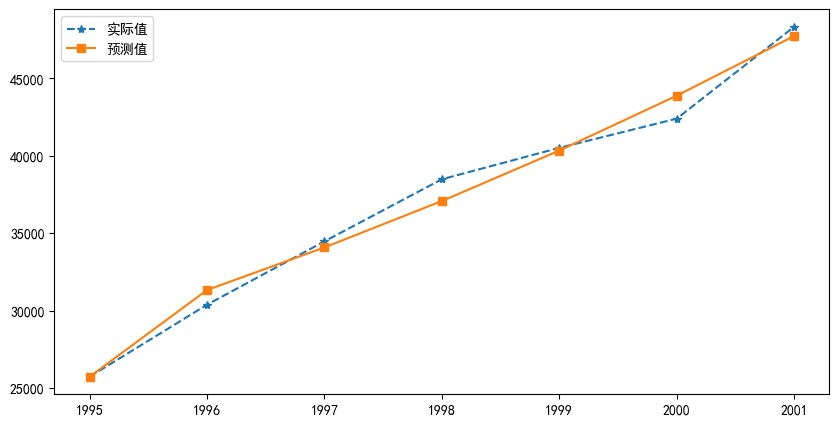

In [17]:
# 绘图
plt.figure(figsize = (10,5))
t0=np.arange(1995,2002)
plt.plot(t0,x0,'*--',label = '实际值')
plt.plot(t0,x_pre[:-1],'s-',label = '预测值')
plt.legend()
plt.show()

### 4.3 GM(1,1) 完整算例



**只适合中短期预测**

1. GM(1, 1)建模
    - 要求: 需要一次累加序列近似为指数规律发展
    - 模型使用数据不是原有数据

2. GM(2, 1), DGM, Verhulst
    - 对于非单调的摆动发展序列或饱和的S形序列.

3. 灰色Verhulst预测模型
    - 用来描述具有饱和状态的S型模型. 常用于人口预测, 生物生长, 繁殖预测, 产品经济寿命预测等.
    
- 已知$x^{(0)}=(x^{(0)}(1),x^{(0)}(2),\cdots,x^{(0)}(n))$
- 累加生成序列:$x^{(1)}=(x^{(0)}(1),x^{(0)}(1)+x^{(0)}(2),\cdots,x^{(0)}(1)+\cdots+x^{(0)}(n))$
- 均值生成序列:$z^{(1)}=(z^{(1)}(1),z^{(1)}(2),\cdots,z^{(1)}(n))$, 其中$z^{(1)}(k)=0.5x^{(1)}(k)+0.5x^{(1)}(k-1)$
- 灰微分方程: $x^{(0)}(k)+az^{(1)}(k)=b,\ k=2,3,\cdots,n$
- 相应白化微分方程: $\frac{dx^{(1)}}{dt}+ax^{(1)}(t)=b$
- 可容覆盖: $\Theta=(e^{-\frac{2}{n+1}}, e^{\frac{2}{n+1}})$

回归参数估计值：
斜率 = 2.372771, 截距 = 0.429800
线性拟合预测值：
[ 2.80257143  5.17534286  7.54811429  9.92088571 12.29365714 14.66642857]
拟合参数值为： [ 7.73729447  0.3363273  -5.80151578]
累加数据拟合值： [ 5.02912665  9.35918617 15.42039096 23.9048479  35.78136618 52.40608213]
累加拟合值累减还原后： [ 5.02912665  4.33005952  6.06120479  8.48445694 11.87651828 16.62471594]
原数据线性拟合MSE: 2.732831180952381
累加数据指数拟合MSE: 0.11388066621177188
指数预测累加数据还原后MSE: 0.39481970716687337


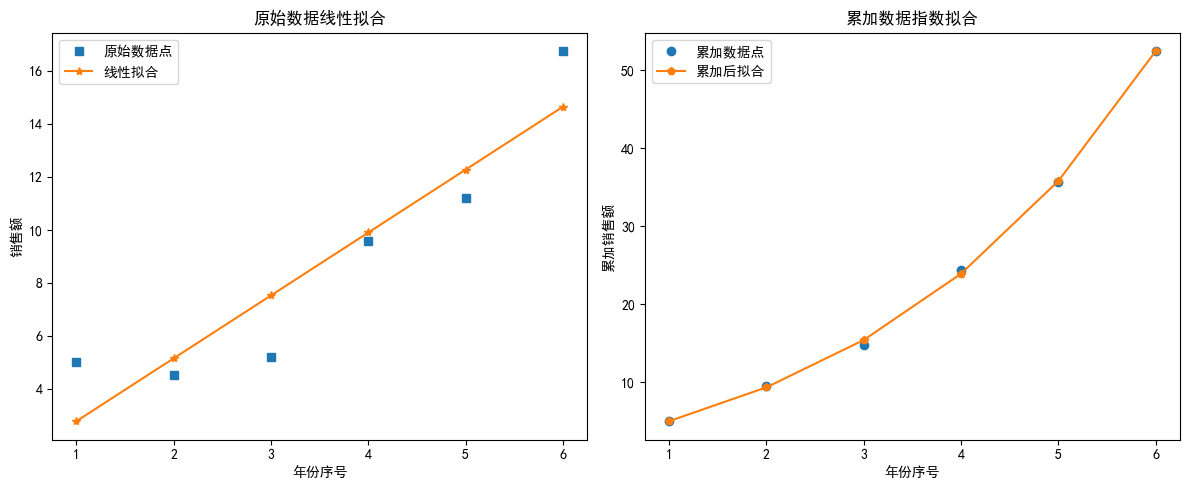

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import warnings

warnings.filterwarnings('ignore')

# 中文显示设置：增加字体回退，避免 SimHei 不存在时报错/警告
plt.rcParams['font.sans-serif'] = [
    'SimHei', 'Microsoft YaHei', 'Arial Unicode MS', 'DejaVu Sans'
]
plt.rcParams['axes.unicode_minus'] = False

t0 = np.arange(1, 7, dtype=float)
x0 = np.array([5.045, 4.536, 5.236, 9.589, 11.239, 16.762], dtype=float)

# =========================
# 1. 原始数据线性拟合
# 不依赖 sklearn，使用 numpy.polyfit
# =========================
coef = np.polyfit(t0, x0, 1)          # coef = [斜率, 截距]
x11 = np.polyval(coef, t0)

print('回归参数估计值：')
print(f'斜率 = {coef[0]:.6f}, 截距 = {coef[1]:.6f}')
print('线性拟合预测值：')
print(x11)

# =========================
# 2. 一次累加生成
# =========================
x1 = np.cumsum(x0)

def func(t, a, b, c):
    return a * np.exp(b * t) + c

# 指数曲线拟合
popt, pcov = curve_fit(func, t0, x1, maxfev=10000)
x12 = func(t0, *popt)

print('拟合参数值为：', popt)
print('累加数据拟合值：', x12)

# =========================
# 3. 累减还原
# =========================
x13 = x12.copy()
x13[1:] = np.diff(x12)
print('累加拟合值累减还原后：', x13)

# =========================
# 4. 计算 MSE
# =========================
def mse(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean((y_true - y_pred) ** 2)

print('原数据线性拟合MSE:', mse(x0, x11))
print('累加数据指数拟合MSE:', mse(x1, x12))
print('指数预测累加数据还原后MSE:', mse(x0, x13))

# =========================
# 5. 绘图
# =========================
plt.figure(figsize=(12, 5))

plt.subplot(121)
h1, = plt.plot(t0, x0, 's', label='原始数据点')
h2, = plt.plot(t0, x11, '*-', label='线性拟合')
plt.legend(handles=[h1, h2], loc='upper left')
plt.title('原始数据线性拟合')
plt.xlabel('年份序号')
plt.ylabel('销售额')

plt.subplot(122)
h3, = plt.plot(t0, x1, 'o', label='累加数据点')
h4, = plt.plot(t0, x12, 'p-', label='累加后拟合')
plt.legend(handles=[h3, h4])
plt.title('累加数据指数拟合')
plt.xlabel('年份序号')
plt.ylabel('累加销售额')

plt.tight_layout()
plt.show()

## 5. 小结

本次实验介绍了数据生成中的数据累加生成的原理，并且基于灰色GM(1,1)模型预测蔬菜产量。

通过本次实验需要掌握以下内容：
- 掌握数据累加生成的原理
- 掌握灰色GM模型的预测